In [18]:
import nltk 
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np
import random

In [19]:
import pandas as pd

df = pd.read_csv("hf://datasets/gsri-18/ISEAR-dataset-complete/ISEAR_dataset_complete.csv")
df = df.drop(columns=["Unnamed: 2"])
content = df["content"]
print(content.head())
emotions = df["emotion"].unique()

0    On days when I feel close to my partner and ot...
1    Every time I imagine that someone I love or I ...
2    When I had been obviously unjustly treated and...
3    When I think about the short time that we live...
4    At a gathering I found myself involuntarily si...
Name: content, dtype: str


In [20]:
# Dataset statistics before tokenization
emotions_unique = df["emotion"].unique()
print("Dataset statistics before tokenization for each unique emotion:")
print()
for emotion in emotions_unique:
    subset = df[df["emotion"] == emotion]
    N = len(subset["emotion"])
    print(f"{emotion} has {N} occurences, {round(N/len(df["emotion"]) * 100, 2)}%")
    average_length = subset["content"].str.len().mean()
    print(f"{emotion} has an average length of {average_length:.2f} characters")
    print()


Dataset statistics before tokenization for each unique emotion:

joy has 1092 occurences, 14.53%
joy has an average length of 103.14 characters

fear has 1076 occurences, 14.32%
fear has an average length of 123.96 characters

anger has 1079 occurences, 14.36%
anger has an average length of 130.65 characters

sadness has 1082 occurences, 14.4%
sadness has an average length of 103.93 characters

disgust has 1066 occurences, 14.18%
disgust has an average length of 114.61 characters

shame has 1071 occurences, 14.25%
shame has an average length of 116.73 characters

guilt has 1050 occurences, 13.97%
guilt has an average length of 124.89 characters



In [21]:
# Representation 1: Tokenization
tokens = []
for element in df["content"]:
    tokenized_sentence = word_tokenize(element)
    tokens.append(tokenized_sentence)
df["tokens"] = tokens


In [22]:
df.head(5)
# print avarage token length of sentence here.

,emotion,content,tokens
0,joy,On days when I feel close to my partner and ot...,"[On, days, when, I, feel, close, to, my, partn..."
1,fear,Every time I imagine that someone I love or I ...,"[Every, time, I, imagine, that, someone, I, lo..."
2,anger,When I had been obviously unjustly treated and...,"[When, I, had, been, obviously, unjustly, trea..."
3,sadness,When I think about the short time that we live...,"[When, I, think, about, the, short, time, that..."
4,disgust,At a gathering I found myself involuntarily si...,"[At, a, gathering, I, found, myself, involunta..."


In [23]:
# Representation 2: Bag of words
vectorizer = CountVectorizer(analyzer=lambda tokens: tokens)

bag_matrix = vectorizer.fit_transform(df["tokens"].tolist())

bag_df = pd.DataFrame(bag_matrix.toarray(),
                      columns=vectorizer.get_feature_names_out(),
                      index=df.index
)

print(bag_df.head(5))

   !  $  %  &  '  ''  'd  'll  'm  're  ...  yr.  yrs  yukky  zero  \
0  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   
1  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   
2  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   
3  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   
4  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   

   zig-zagging  zip  zipper  zombies  zone  zoophiliac  
0            0    0       0        0     0           0  
1            0    0       0        0     0           0  
2            0    0       0        0     0           0  
3            0    0       0        0     0           0  
4            0    0       0        0     0           0  

[5 rows x 10173 columns]


In [24]:
# Representation 3: Bigrams

bigrams = []
for sentence in df["tokens"]:
    bigrams_per_sentence = []
    for i in range(len(sentence) - 1):
        bigram = sentence[i] + " " + sentence[i+1]
        bigrams_per_sentence.append(bigram)
    bigrams.append(bigrams_per_sentence)
df["bigrams"] = bigrams

In [25]:
# Representation 4: Trigrams

trigrams = []
for sentence in df["tokens"]:
    trigrams_per_sentence = []
    for i in range(len(sentence) - 2):
        trigram = sentence[i] + " " + sentence[i+1] + " " + sentence[i+2]
        trigrams_per_sentence.append(trigram)
    trigrams.append(trigrams_per_sentence)
df["trigrams"] = trigrams

In [26]:
print(df["trigrams"][0])

['On days when', 'days when I', 'when I feel', 'I feel close', 'feel close to', 'close to my', 'to my partner', 'my partner and', 'partner and other', 'and other friends', 'other friends .', 'friends . When', '. When I', 'When I feel', 'I feel at', 'feel at peace', 'at peace with', 'peace with myself', 'with myself and', 'myself and also', 'and also experience', 'also experience a', 'experience a close', 'a close contact', 'close contact with', 'contact with people', 'with people whom', 'people whom I', 'whom I regard', 'I regard greatly', 'regard greatly .']


In [27]:
# Architecture 1: Log-Linear
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
texts = df["content"].fillna("")
labels = sorted(df["emotion"].unique())
label_to_id = {label: i for i, label in enumerate(labels)}
y = df["emotion"].map(label_to_id)


token_indicator_model = Pipeline([
    ("features", CountVectorizer(
        tokenizer=word_tokenize,
        token_pattern=None,
        binary=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        C=1.0
    ))
])

# I chose for StratifiedKFold to keep the even emotion distrubition of the dataset in every fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

results = cross_validate(
    token_indicator_model,
    texts,
    y,
    cv=cv,
    scoring=["accuracy"],
    return_train_score=True
)

print("Validation accuracy:", results["test_accuracy"])
print("Mean accuracy:", results["test_accuracy"].mean())

Validation accuracy: [0.58976064 0.56220892 0.57950765 0.56819694 0.58150366]
Mean accuracy: 0.5762355607933071


In [28]:
# Cell to compare the three representations when used in logistic regression
models = {
    "token-indicator": Pipeline([
        ("features", CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            binary=True,
            ngram_range=(1, 1)
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),
    "bag-of-words": Pipeline([
        ("features", CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            binary=False,
            ngram_range=(1, 1)
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),
    "bigrams-and-trigrams": Pipeline([
        ("features", CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            binary=False,
            ngram_range=(2, 3)
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),
    "unigrams-bigrams-and-trigrams": Pipeline([ # I'm testing if the scores improve when adding unigrams
            ("features", CountVectorizer(
                tokenizer=word_tokenize,
                token_pattern=None,
                binary=False,
                ngram_range=(1, 3)
            )),
            ("classifier", LogisticRegression(max_iter=2000))
        ])
}

scores = {}

for name, model in models.items():
    result = cross_validate(
        model,
        texts,
        y,
        cv=cv,
        scoring=["accuracy"],
        return_train_score=True
    )
    scores[name] = result["test_accuracy"]
    print(
        f"{name}: "
        f"accuracy = {result['test_accuracy'].mean():.4f}, "
    )

token-indicator: accuracy = 0.5762, 
bag-of-words: accuracy = 0.5760, 
bigrams-and-trigrams: accuracy = 0.5250, 
unigrams-bigrams-and-trigrams: accuracy = 0.5804, 


In [29]:
# classes and functions for mlp
import itertools
nltk.download("punkt_tab")

corpus = " ".join(df["content"].fillna("").astype(str))

vocab = sorted(set(word_tokenize(corpus)))
token_to_id = {token: i for i, token in enumerate(vocab)}

class Encoder:
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

def cross_validation_split(pairs, k, seed=0):
    """
    Shuffles a list of labelled texts and splits the result into k folds.
    
    pairs: lists of tuples (text, label)
    k: number of folds
    seed: for reproducible shuffling
    """
    
    # Shuffle the pairs
    random.seed(seed)
    pairs = list(pairs)
    ids = list(range(len(pairs)))
    random.shuffle(ids)

    # Split without coercing (text, int) tuples into a string array
    ids_parts = np.array_split(np.array(ids, dtype=object), k)
    
    # Create a dictionary to store the training and validation sets for each fold
    cross_validation_sets = {}
    for i in range(k):
        validation_set = [pairs[j] for j in ids_parts[i]] 
        training_ids = list(itertools.chain.from_iterable(part for k, part in enumerate(ids_parts) if k != i))
        training_set = [pairs[j] for j in training_ids]
        cross_validation_sets[i] = {
            "training": training_set, 
            "validation": validation_set, 
            'training_ids': training_ids,   # these are not often needed, but we return it just in case
            'validation_ids': ids_parts[i]  # these are not often needed, but we return it just in case
        }

    return cross_validation_sets

my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

# for seed in my_seeds:  
#     my_cross_validation_sets.append(
#         cross_validation_split(
#             # we pair the texts with their labels
#             pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
#             k=num_folds,
#             seed=seed
#         )
#     )

class TokenIndicator(Encoder):
    def __init__(self, token_to_id):
        self.token_to_id = token_to_id

    def __len__(self):
        return len(self.token_to_id)

    def __call__(self, x: str) -> np.ndarray:
        vector = np.zeros(len(self), dtype=np.float32)

        for token in set(word_tokenize(x)):
            token_id = self.token_to_id.get(token)
            if token_id is not None:
                vector[token_id] = 1

        return vector
    
token_indicator_encoder = TokenIndicator(token_to_id)
doc_repr = token_indicator_encoder(corpus)

print(len(doc_repr))
print(doc_repr.sum())

[nltk_data] Downloading package punkt_tab to /home/colin/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


10176
10176.0


In [30]:
import os
results_folder = "../Data/Results"
os.makedirs(results_folder, exist_ok=True)

In [ ]:
# Architecture 2: Single hidden layer MLP
import smlp

class CountVectorizerEncoder(Encoder):
    def __init__(self, vectorizer):
        self.vectorizer = vectorizer

    def __len__(self):
        return len(self.vectorizer.vocabulary_)

    def __call__(self, x: str) -> np.ndarray:
        return self.vectorizer.transform([x]).toarray().ravel()

labels = sorted(df["emotion"].unique())
pairs = [(content, labels.index(emotion)) for content, emotion in zip(df["content"], df["emotion"])]
cv = cross_validation_split(pairs, k=num_folds, seed=0)

# Settings for encoders for token indicator, BOW and unigrams + trigrams (capped due to memory issues).
encoder_configs = {
    "token-indicator": {
        "binary": True,
        "ngram_range": (1, 1),
    },
    "bag-of-words": {
        "binary": False,
        "ngram_range": (1, 1),
    },
    "bigrams-and-trigrams": {
        "binary": False,
        "ngram_range": (1, 2),
        "max_features": 50000
    },
}

results = {name: [] for name in encoder_configs}
encoder_accuracy = {}
# For each encoder run the model with hidden dim of 128 with cross validation.
for encoder_name, config in encoder_configs.items():
    mean_accuracy = []
    for fold in cv:
        print(encoder_name)
        training = cv[fold]["training"]
        validation = cv[fold]["validation"]

        vectorizer = CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            **config,
        )
        print("Fitting vectorizer")
        vectorizer.fit([content for content, label in training])
        print("Vocabulary size:", len(vectorizer.vocabulary_))
        print("Training MLP")
        encoder = CountVectorizerEncoder(vectorizer)

        metrics, best_epoch, best_pred = smlp.train_neural_network_model(
            training,
            validation,
            num_classes=len(labels),
            encoder=encoder,
            save_to=f"{results_folder}/mlp_{encoder_name}_{fold}_test",
            num_epochs=10,
        )

        results[encoder_name].append(
                    {
                        "metrics": metrics,
                        "best_epoch": best_epoch,
                        "best_pred": best_pred,
                    })

        best_val_acc_this_fold = max(epoch_data["val_metrics"]["accuracy"] for epoch_data in metrics)
        mean_accuracy.append(best_val_acc_this_fold)
    encoder_accuracy[f"{encoder_name}"] = np.mean(mean_accuracy)
print(mean_accuracy)


token-indicator
Fitting vectorizer
Vocabulary size: 8343
Training MLP
Transforming documents...
Document transformation done! Time taken: 2.569 seconds
Dataloader done! Time taken: 0.319 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7978 | train acc: 0.3967 | val loss: 1.5546 | val acc: 0.5359
Epoch 02 | train loss: 1.1829 | train acc: 0.6743 | val loss: 1.2269 | val acc: 0.5771
Epoch 03 | train loss: 0.7665 | train acc: 0.7883 | val loss: 1.1634 | val acc: 0.5891
Epoch 04 | train loss: 0.5381 | train acc: 0.8560 | val loss: 1.1747 | val acc: 0.5911
Epoch 05 | train loss: 0.3982 | train acc: 0.9004 | val loss: 1.2280 | val acc: 0.5864
Epoch 06 | train loss: 0.3016 | train acc: 0.9253 | val loss: 1.2898 | val acc: 0.5844
Epoch 07 | train loss: 0.2334 | train acc: 0.9479 | val loss: 1.3716 | val acc: 0.5818
Epoch 08 | train loss: 0.1866 | train acc: 0.9614 | val loss: 1.4291 | val acc: 0.5758
Epoch 09 | train loss: 0.1516 | train acc: 0.9694 | val loss: 1.5104 | val acc: 0.5765
Epoch 10 | train loss: 0.1235 | train acc: 0.9767 | val loss: 1.5793 | val acc: 0.5751
Training done! Time taken: 10.974 seconds
token-indicator
Fitting vectorizer
Vocabulary size: 8399
Training MLP
Transforming docum

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7984 | train acc: 0.4000 | val loss: 1.5447 | val acc: 0.5216
Epoch 02 | train loss: 1.1788 | train acc: 0.6649 | val loss: 1.2222 | val acc: 0.5828
Epoch 03 | train loss: 0.7658 | train acc: 0.7873 | val loss: 1.1602 | val acc: 0.5902
Epoch 04 | train loss: 0.5380 | train acc: 0.8586 | val loss: 1.1758 | val acc: 0.5888
Epoch 05 | train loss: 0.4000 | train acc: 0.9005 | val loss: 1.2143 | val acc: 0.5842
Epoch 06 | train loss: 0.3045 | train acc: 0.9287 | val loss: 1.2700 | val acc: 0.5782
Epoch 07 | train loss: 0.2364 | train acc: 0.9476 | val loss: 1.3394 | val acc: 0.5775
Epoch 08 | train loss: 0.1902 | train acc: 0.9608 | val loss: 1.3928 | val acc: 0.5729
Epoch 09 | train loss: 0.1565 | train acc: 0.9661 | val loss: 1.4549 | val acc: 0.5695
Epoch 10 | train loss: 0.1294 | train acc: 0.9731 | val loss: 1.5189 | val acc: 0.5655
Training done! Time taken: 10.834 seconds
token-indicator
Fitting vectorizer
Vocabulary size: 8413
Training MLP
Transforming docum

  0%|          | 0/10 [00:00<?, ?it/s]

... (19 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6838 | train acc: 0.4529 | val loss: 1.3756 | val acc: 0.5516
Epoch 02 | train loss: 0.7073 | train acc: 0.8483 | val loss: 1.1748 | val acc: 0.5835
Epoch 03 | train loss: 0.2312 | train acc: 0.9659 | val loss: 1.1855 | val acc: 0.5888
Epoch 04 | train loss: 0.0953 | train acc: 0.9910 | val loss: 1.2346 | val acc: 0.5835
Epoch 05 | train loss: 0.0508 | train acc: 0.9957 | val loss: 1.2907 | val acc: 0.5808
Epoch 06 | train loss: 0.0315 | train acc: 0.9975 | val loss: 1.3386 | val acc: 0.5888
Epoch 07 | train loss: 0.0218 | train acc: 0.9980 | val loss: 1.3734 | val acc: 0.5888
Epoch 08 | train loss: 0.0161 | train acc: 0.9985 | val loss: 1.4102 | val acc: 0.5802
Epoch 09 | train loss: 0.0133 | train acc: 0.9987 | val loss: 1.4475 | val acc: 0.5802
Epoch 10 | train loss: 0.0120 | train acc: 0.9983 | val loss: 1.4775 | val acc: 0.5802
Training done! Time taken: 56.179 seconds
bigrams-and-trigrams
Fitting vectorizer
Vocabulary size: 50000
Training MLP
Transforming

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6801 | train acc: 0.4479 | val loss: 1.3538 | val acc: 0.5902
Epoch 02 | train loss: 0.6839 | train acc: 0.8546 | val loss: 1.1458 | val acc: 0.6094
Epoch 03 | train loss: 0.2271 | train acc: 0.9666 | val loss: 1.1489 | val acc: 0.6028
Epoch 04 | train loss: 0.0977 | train acc: 0.9884 | val loss: 1.1844 | val acc: 0.5995
Epoch 05 | train loss: 0.0516 | train acc: 0.9957 | val loss: 1.2321 | val acc: 0.5975
Epoch 06 | train loss: 0.0324 | train acc: 0.9968 | val loss: 1.2728 | val acc: 0.5935
Epoch 07 | train loss: 0.0228 | train acc: 0.9977 | val loss: 1.3113 | val acc: 0.5921
Epoch 08 | train loss: 0.0169 | train acc: 0.9975 | val loss: 1.3587 | val acc: 0.5815
Epoch 09 | train loss: 0.0126 | train acc: 0.9987 | val loss: 1.3797 | val acc: 0.5862
Epoch 10 | train loss: 0.0111 | train acc: 0.9983 | val loss: 1.4230 | val acc: 0.5802
Training done! Time taken: 52.328 seconds
bigrams-and-trigrams
Fitting vectorizer
Vocabulary size: 50000
Training MLP
Transforming

In [ ]:
import analysis

# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([fold["metrics"][fold["best_epoch"]]["val_metrics"]["accuracy"] for fold in data[sys_name]])

posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(results, 'token-indicator'),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(results, 'bag-of-words'),  # this will have shape [num_runs * num_folds]
    names=["mlp-indicator-enc", "mlp-bow"]
)

p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005) 

In [ ]:
# Architecture 3: Modified MLP - 2 hidden layers

import smlp_mod
class CountVectorizerEncoder(Encoder):
    def __init__(self, vectorizer):
        self.vectorizer = vectorizer

    def __len__(self):
        return len(self.vectorizer.vocabulary_)

    def __call__(self, x: str) -> np.ndarray:
        return self.vectorizer.transform([x]).toarray().ravel()

labels = sorted(df["emotion"].unique())
pairs = [(content, labels.index(emotion)) for content, emotion in zip(df["content"], df["emotion"])]
cv = cross_validation_split(pairs, k=num_folds, seed=0)

encoder_configs = {
    "token-indicator": {
        "binary": True,
        "ngram_range": (1, 1),
    },
    "bag-of-words": {
        "binary": False,
        "ngram_range": (1, 1),
    },
    "bigrams-and-trigrams": {
        "binary": False,
        "ngram_range": (1, 2),
        "max_features": 50000
    },
}

results = {name: [] for name in encoder_configs}

encoder_accuracy_mod = {}
for encoder_name, config in encoder_configs.items():
    mean_accuracy = []
    for fold in cv:
        print(encoder_name)
        training = cv[fold]["training"]
        validation = cv[fold]["validation"]

        vectorizer = CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            **config,
        )
        vectorizer.fit([content for content, label in training])
        print("Vocabulary size:", len(vectorizer.vocabulary_))
        encoder = CountVectorizerEncoder(vectorizer)

        metrics, best_epoch, best_pred = smlp_mod.train_neural_network_model(
            training,
            validation,
            num_classes=len(labels),
            encoder=encoder,
            save_to=f"{results_folder}/mlp_{encoder_name}_{fold}_test",
            num_epochs=10,
        )

        results[encoder_name].append(
            {
                "metrics": metrics,
                "best_epoch": best_epoch,
                "best_pred": best_pred,
            }
        )

        best_val_acc_this_fold = max(epoch_data["val_metrics"]["accuracy"] for epoch_data in metrics)
        mean_accuracy.append(best_val_acc_this_fold)
    encoder_accuracy_mod[f"{encoder_name}"] = np.mean(mean_accuracy)



token-indicator
Vocabulary size: 8343
Transforming documents...
Document transformation done! Time taken: 1.663 seconds
Dataloader done! Time taken: 0.208 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7939 | train acc: 0.3530 | val loss: 1.4380 | val acc: 0.5259
Epoch 02 | train loss: 1.0198 | train acc: 0.6613 | val loss: 1.1864 | val acc: 0.5771
Epoch 03 | train loss: 0.5627 | train acc: 0.8234 | val loss: 1.2643 | val acc: 0.5904
Epoch 04 | train loss: 0.3353 | train acc: 0.8994 | val loss: 1.3929 | val acc: 0.5858
Epoch 05 | train loss: 0.2137 | train acc: 0.9429 | val loss: 1.6179 | val acc: 0.5751
Epoch 06 | train loss: 0.1376 | train acc: 0.9636 | val loss: 1.7685 | val acc: 0.5731
Epoch 07 | train loss: 0.0939 | train acc: 0.9764 | val loss: 1.9387 | val acc: 0.5632
Epoch 08 | train loss: 0.0665 | train acc: 0.9847 | val loss: 2.0844 | val acc: 0.5638
Epoch 09 | train loss: 0.0498 | train acc: 0.9879 | val loss: 2.2352 | val acc: 0.5578
Epoch 10 | train loss: 0.0409 | train acc: 0.9894 | val loss: 2.3921 | val acc: 0.5539
Training done! Time taken: 8.190 seconds
token-indicator
Vocabulary size: 8399
Transforming documents...
Document transformation d

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7750 | train acc: 0.3496 | val loss: 1.4305 | val acc: 0.5130
Epoch 02 | train loss: 1.0348 | train acc: 0.6549 | val loss: 1.1905 | val acc: 0.5902
Epoch 03 | train loss: 0.5808 | train acc: 0.8141 | val loss: 1.2730 | val acc: 0.5848
Epoch 04 | train loss: 0.3424 | train acc: 0.9004 | val loss: 1.4022 | val acc: 0.5782
Epoch 05 | train loss: 0.2180 | train acc: 0.9393 | val loss: 1.5371 | val acc: 0.5768
Epoch 06 | train loss: 0.1472 | train acc: 0.9622 | val loss: 1.7276 | val acc: 0.5629
Epoch 07 | train loss: 0.1004 | train acc: 0.9757 | val loss: 1.8693 | val acc: 0.5522
Epoch 08 | train loss: 0.0763 | train acc: 0.9835 | val loss: 2.0132 | val acc: 0.5476
Epoch 09 | train loss: 0.0572 | train acc: 0.9864 | val loss: 2.1227 | val acc: 0.5429
Epoch 10 | train loss: 0.0453 | train acc: 0.9887 | val loss: 2.2850 | val acc: 0.5429
Training done! Time taken: 8.118 seconds
token-indicator
Vocabulary size: 8413
Transforming documents...
Document transformation d

  0%|          | 0/10 [00:00<?, ?it/s]

... (21 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6847 | train acc: 0.3945 | val loss: 1.2987 | val acc: 0.5576
Epoch 02 | train loss: 0.5400 | train acc: 0.8480 | val loss: 1.2042 | val acc: 0.5935
Epoch 03 | train loss: 0.0998 | train acc: 0.9797 | val loss: 1.3806 | val acc: 0.5702
Epoch 04 | train loss: 0.0322 | train acc: 0.9952 | val loss: 1.4601 | val acc: 0.5689
Epoch 05 | train loss: 0.0150 | train acc: 0.9978 | val loss: 1.5278 | val acc: 0.5702
Epoch 06 | train loss: 0.0123 | train acc: 0.9975 | val loss: 1.6072 | val acc: 0.5682
Epoch 07 | train loss: 0.0089 | train acc: 0.9985 | val loss: 1.6714 | val acc: 0.5722
Epoch 08 | train loss: 0.0073 | train acc: 0.9985 | val loss: 1.7640 | val acc: 0.5755
Epoch 09 | train loss: 0.0058 | train acc: 0.9985 | val loss: 1.8063 | val acc: 0.5669
Epoch 10 | train loss: 0.0061 | train acc: 0.9980 | val loss: 1.8316 | val acc: 0.5715
Training done! Time taken: 39.760 seconds
bigrams-and-trigrams
Vocabulary size: 58621
Transforming documents...
Document transform

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6935 | train acc: 0.4048 | val loss: 1.2614 | val acc: 0.5609
Epoch 02 | train loss: 0.5376 | train acc: 0.8555 | val loss: 1.1764 | val acc: 0.6008
Epoch 03 | train loss: 0.0997 | train acc: 0.9787 | val loss: 1.2784 | val acc: 0.6041
Epoch 04 | train loss: 0.0310 | train acc: 0.9940 | val loss: 1.3904 | val acc: 0.6114
Epoch 05 | train loss: 0.0151 | train acc: 0.9973 | val loss: 1.4837 | val acc: 0.6081
Epoch 06 | train loss: 0.0119 | train acc: 0.9985 | val loss: 1.5570 | val acc: 0.6094
Epoch 07 | train loss: 0.0094 | train acc: 0.9977 | val loss: 1.5949 | val acc: 0.6001
Epoch 08 | train loss: 0.0082 | train acc: 0.9980 | val loss: 1.6591 | val acc: 0.5975
Epoch 09 | train loss: 0.0083 | train acc: 0.9983 | val loss: 1.6943 | val acc: 0.5961
Epoch 10 | train loss: 0.0063 | train acc: 0.9983 | val loss: 1.7369 | val acc: 0.6001
Training done! Time taken: 39.116 seconds


In [ ]:
print(encoder_accuracy_mod)

{'token-indicator': np.float64(0.5927358049857732), 'bag-of-words': np.float64(0.5890110735974858), 'bigrams-and-trigrams': np.float64(0.5923365149134355)}


A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=0.5797 P(Tie)=0.3054 P(B wins)=0.1149 Effect Size=-0.81


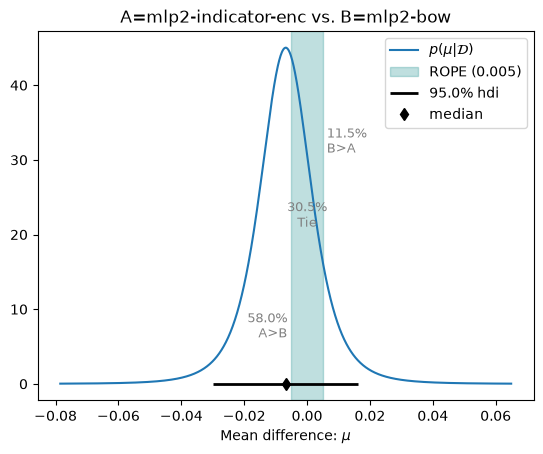

In [ ]:
posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(results, 'token-indicator'),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(results, 'bag-of-words'),  # this will have shape [num_runs * num_folds]
    names=["mlp2-indicator-enc", "mlp2-bow"]
)

p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005) 